In [4]:
%load_ext autoreload
%autoreload 2

In [23]:
import numpy as np
from pygraphon.graphons import StepGraphon
from pygraphon.estimators import SmoothNetHist

from utils_generators import AssociativeFullyRandom
from pygraphon.norm import MseProbaEdge, MaeProbaEdge, AUCEdge, AUPRCEdge
import matplotlib.pyplot as plt
from pygraphon.plots.plot_matrices import spy


# Initialisation

In [18]:
n = 100
k = 2
theta_intra_min, theta_intra_max = 0.5, 0.7
theta_inter_min, theta_inter_max = 0.05, 0.2
theta = AssociativeFullyRandom(
                    K=k,
                    min_inside_classes=theta_intra_min,
                    max_inside_classes=theta_intra_max,
                    min_outside_classes=theta_inter_min,
                    max_outside_classes=theta_inter_max,
                )
print(theta.Theta)
graphon = StepGraphon(theta.Theta, bandwidthHist=1 / k)
adjacency_matrix = graphon.draw(n=n, exchangeable=False)

[[0.69784833 0.11536911]
 [0.11536911 0.61915275]]


# Olhede fit

In [19]:
est = SmoothNetHist()
first_hist_olhede = est._first_approximate_graphon_from_adjacency(adjacencyMatrix= adjacency_matrix)

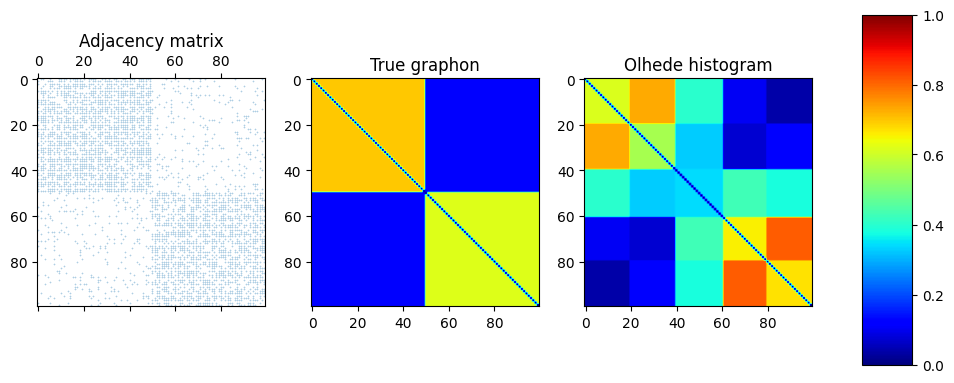

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(first_hist_olhede[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.show()

Edge density:  0.6244897959183674
Edge density:  0.7028571428571428
Edge density:  0.11346938775510204


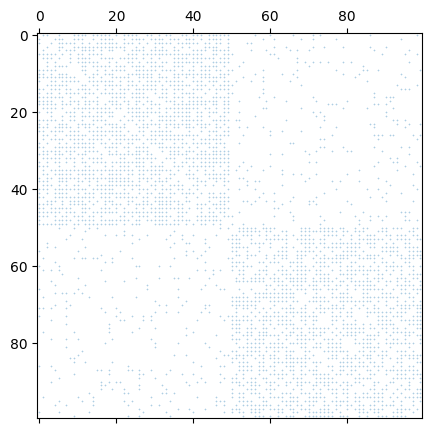

In [21]:
from pygraphon.utils import edge_density
spy(adjacency_matrix)
print("Edge density: ", edge_density(adjacency_matrix[int(n/2):, int(n/2):]))
print("Edge density: ", edge_density(adjacency_matrix[:int(n/2), :int(n/2)]))
print("Edge density: ", edge_density(adjacency_matrix[:int(n/2), int(n/2):]))

# Smooth NetHist fit 

In [22]:
my_est = SmoothNetHist()
my_est.fit(adjacency_matrix)

In [23]:
my_est._first_fit_graphon

In [24]:
print("Ratio of parameters:", my_est.get_ratio_par())
print("Number of unique parameters in SmoothNetHist:", len(np.unique(my_est.graphon.get_graphon())))
print("Number of unique parameters in Olhede:", len(np.unique(first_hist_olhede[0].get_graphon())))


Ratio of parameters: 0.4
Number of unique parameters in SmoothNetHist: 6
Number of unique parameters in Olhede: 15


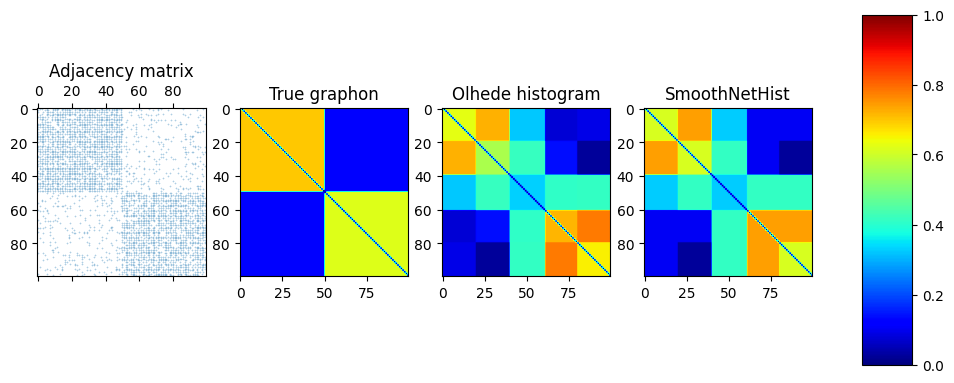

In [25]:
fig, ax = plt.subplots(1, 4, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(my_est._first_fit_graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im3 = ax[3].imshow(my_est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
ax[3].set_title("SmoothNetHist")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.colorbar(im3, cax=cbar_ax)
plt.show()

In [26]:
my_est._first_fit_graphon

In [27]:
norm_olhede_mse = MseProbaEdge(n_nodes=n)(graphon, my_est._first_fit_graphon)
norm_olhede_mae = MaeProbaEdge(n_nodes=n)(graphon, my_est._first_fit_graphon)
norm_olhede_auc = AUCEdge(n_nodes=n)(adjacency_matrix, my_est._first_fit_graphon.get_edge_probabilities(n,False,True))
norm_olhede_auprc = AUPRCEdge(n_nodes=n)(adjacency_matrix, my_est._first_fit_graphon.get_edge_probabilities(n,False,True))

norm_smoothnet_mse = MseProbaEdge(n_nodes=n)(graphon, my_est.graphon)
norm_smoothnet_mae = MaeProbaEdge(n_nodes=n)(graphon, my_est.graphon)
norm_smoothnet_auc = AUCEdge(n_nodes=n)(adjacency_matrix, my_est.graphon.get_edge_probabilities(n,False,True))
norm_smoothnet_auprc = AUPRCEdge(n_nodes=n)(adjacency_matrix, my_est.graphon.get_edge_probabilities(n,False,True))

print("MSE Olhede vs SmoothNetHist:", norm_olhede_mse, norm_smoothnet_mse)
print("MAE Olhede vs SmoothNetHist:", norm_olhede_mae, norm_smoothnet_mae)
print("AUC Olhede vs SmoothNetHist:", norm_olhede_auc, norm_smoothnet_auc)
print("AUPRC Olhede vs SmoothNetHist:", norm_olhede_auprc, norm_smoothnet_auprc)

MSE Olhede vs SmoothNetHist: 0.03282085454154603 0.031584442573762216
MAE Olhede vs SmoothNetHist: 0.14242119123014516 0.13550807243753638
AUC Olhede vs SmoothNetHist: 0.7492253754752064 0.7513008691657884
AUPRC Olhede vs SmoothNetHist: 0.5932950453128858 0.5890950501938359


# SmoothNetHist step by step

In [28]:
new_est = SmoothNetHist()
finite_est = new_est._approximate_graphon_from_adjacency(adjacencyMatrix= adjacency_matrix, number_link_communities= int((k+1)*k/2))


UnboundLocalError: local variable 'best_num_link' referenced before assignment

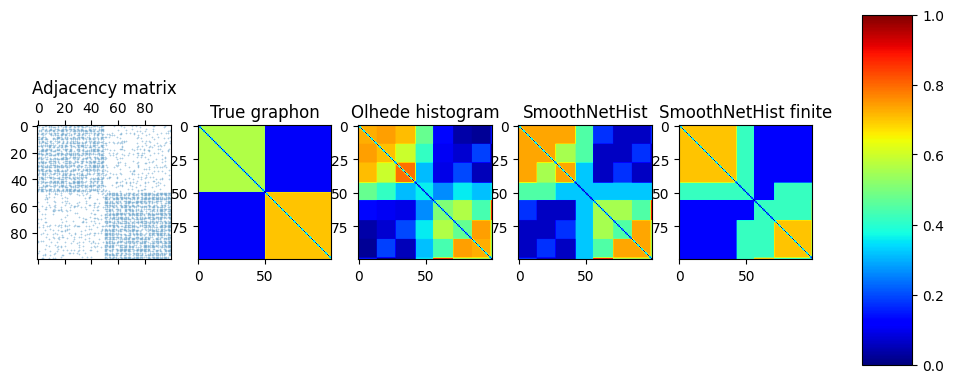

In [ ]:
fig, ax = plt.subplots(1, 5, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(my_est._first_fit_graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im3 = ax[3].imshow(my_est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im4 = ax[4].imshow(finite_est[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
ax[3].set_title("SmoothNetHist")
ax[4].set_title("SmoothNetHist finite")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.colorbar(im3, cax=cbar_ax)
plt.colorbar(im4, cax=cbar_ax)
plt.show()

In [ ]:
norm_smoothnet_mse_true = MseProbaEdge(n_nodes=n)(graphon, finite_est[0])
norm_smoothnet_mae_true = MaeProbaEdge(n_nodes=n)(graphon, finite_est[0])
norm_smoothnet_auc_true = AUCEdge(n_nodes=n)(adjacency_matrix, finite_est[0].get_edge_probabilities(n,False,True))
norm_smoothnet_auprc_true = AUPRCEdge(n_nodes=n)(adjacency_matrix, finite_est[0].get_edge_probabilities(n,False,True))

print("MSE Olhede vs SmoothNetHist vs Corrected:", norm_olhede_mse, norm_smoothnet_mse, norm_smoothnet_mse_true)
print("MAE Olhede vs SmoothNetHist vs Corrected:", norm_olhede_mae, norm_smoothnet_mae, norm_smoothnet_mae_true)
print("AUC Olhede vs SmoothNetHist vs Corrected:", norm_olhede_auc, norm_smoothnet_auc, norm_smoothnet_auc_true)
print("AUPRC Olhede vs SmoothNetHist vs Corrected:", norm_olhede_auprc, norm_smoothnet_auprc, norm_smoothnet_auprc_true)

MSE Olhede vs SmoothNetHist vs Corrected: 0.029630849703642822 0.02855307064754858 0.03276672174852709
MAE Olhede vs SmoothNetHist vs Corrected: 0.1360940333184312 0.13492934762140063 0.12023170546799998
AUC Olhede vs SmoothNetHist vs Corrected: 0.742288047983753 0.7424548740031043 0.7217778922512226
AUPRC Olhede vs SmoothNetHist vs Corrected: 0.5576112908614713 0.5500766272159605 0.5242108336288342


# Other plots for paper

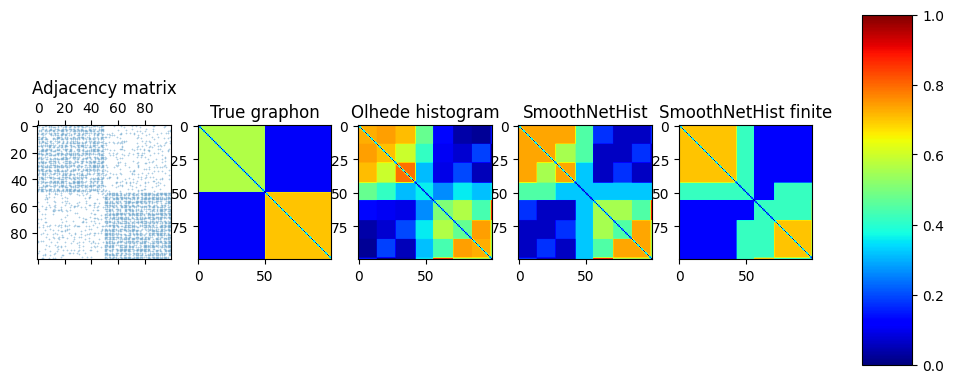

In [ ]:
fig, ax = plt.subplots(1, 5, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(my_est._first_fit_graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im3 = ax[3].imshow(my_est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im4 = ax[4].imshow(finite_est[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
ax[3].set_title("SmoothNetHist")
ax[4].set_title("SmoothNetHist finite")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.colorbar(im3, cax=cbar_ax)
plt.colorbar(im4, cax=cbar_ax)
plt.show()

# Polblog

In [6]:
import io
from zipfile import ZipFile
import requests
import pandas as pd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

url =  "https://networks.skewed.de/net/polblogs/files/polblogs.csv.zip"
response = requests.get(url, stream=False)
with ZipFile(io.BytesIO(response.content)) as myzip:
   with myzip.open(myzip.namelist()[0]) as myfile:
      df = pd.read_csv(myfile)
   with myzip.open(myzip.namelist()[1]) as myfile:
      df2 = pd.read_csv(myfile)

df.columns = ["source", "target"]
df2.columns = [s.replace(" ","") for s in df2.columns]
z = df2["value"].values

   
#df2.columns = ["value"] # 0 for liberals, 1 for conservative
G = nx.from_pandas_edgelist(df, "source", "target")
A = nx.to_numpy_array(G, nodelist=sorted(G.nodes()))
# we remove the diagonal to avoid self-loops
A -= np.diag(np.diag(A))

In [2]:
for index, row in df.iterrows():
    u = row["source"]
    v = row["target"] 
    if not G.has_edge(u, v):
        print("missing edge", u, v)
    if not G.has_edge(v, u):
        print("missing edge", v, u)

(<Figure size 500x500 with 1 Axes>, <AxesSubplot:>)

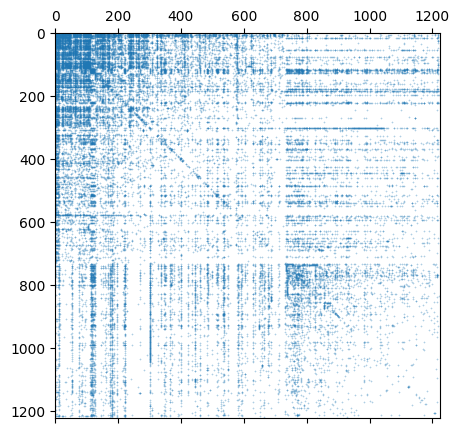

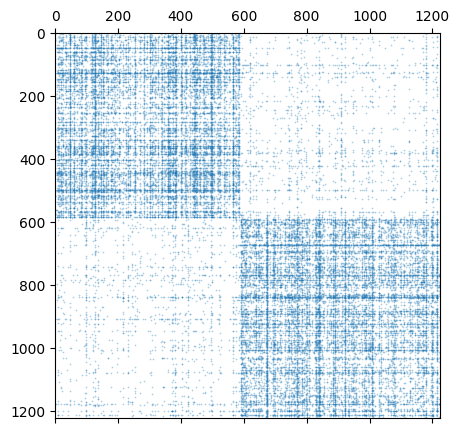

In [3]:
#To check if Sofia is correct also
import networkx as nx
import numpy as np
from pygraphon.plots.plot_matrices import spy

# Load the edge list into a NetworkX graph
G_txt = nx.read_edgelist("polblogs.txt")

# Convert the graph into an adjacency matrix
adjacency_matrix = nx.to_numpy_array(G_txt)

# If you want to represent the adjacency matrix as a NumPy array:
A_olhede = np.array(adjacency_matrix)
A_olhede -= np.diag(np.diag(A_olhede))

spy(A_olhede)
spy(A)

In [146]:
from rpy2.robjects import default_converter
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter


from rpy2.robjects import pandas2ri
from rpy2 import robjects
pandas2ri.activate()

# load your file
robjects.r['data']('polblog_edgelist.rda')


# use the default conversion rules to which the pandas conversion
# is added
with localconverter(default_converter + pandas2ri.converter) as cv:
    dataf = robjects.r["polblog_edgelist"]

robjects.r['data']('polblog.rda')
# use the default conversion rules to which the pandas conversion
# is added
with localconverter(default_converter + pandas2ri.converter) as cv:
    data_all = robjects.r["polblog"]

   
#df2.columns = ["value"] # 0 for liberals, 1 for conservative
G_R = nx.from_pandas_edgelist(dataf, "V1", "V2")
A_R = nx.to_numpy_array(G_R)
# we remove the diagonal to avoid self-loops
A_R -= np.diag(np.diag(A_R))

In [55]:
num_liberals = np.sum(z == 0)
num_conservatives = np.sum(z == 1)
print(num_conservatives)
print(num_liberals)

732
758


Trying to replicate the plots by sorting into 4 categories

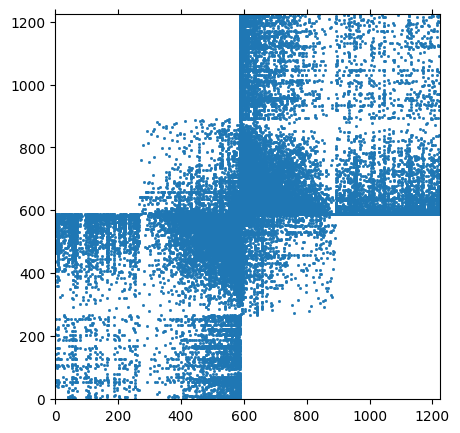

In [29]:
import networkx as nx
from random import shuffle

# Compute the degrees of the nodes
degrees = dict(G.degree())

def check_cross_citation(graph,node):
    neighbors = graph.neighbors(node)
    for neighbor in neighbors:
        if z[node] != z[neighbor]:
            return True
    return False

# Sort nodes by increasing degrees within each membership group
nodes_0_0 = [node for node in G.nodes() if z[node] == 0 and not check_cross_citation(G,node)]
nodes_0_1 = [node for node in G.nodes() if z[node] == 0 and check_cross_citation(G,node)]
nodes_1_0 = [node for node in G.nodes() if z[node] == 1 and  check_cross_citation(G,node)]
nodes_1_1 = [node for node in G.nodes() if z[node] == 1 and not check_cross_citation(G,node)]

shuffle(nodes_0_0)
shuffle(nodes_1_1)

nodes_0_0_sorted = nodes_0_0 #sorted(nodes_0_0, key=lambda node: degrees[node])
nodes_0_1_sorted = sorted(nodes_0_1, key=lambda node: degrees[node])
nodes_1_0_sorted = sorted(nodes_1_0, key=lambda node: degrees[node], reverse=True)
nodes_1_1_sorted = nodes_1_1 # sorted(nodes_1_1, key=lambda node: degrees[node], reverse=False)

# Create the reordered adjacency matrix
reordered_A = nx.adjacency_matrix(G, nodelist=nodes_0_0_sorted + nodes_0_1_sorted + nodes_1_0_sorted + nodes_1_1_sorted).toarray()

spy(reordered_A, marker_size=1, origin="lower")
plt.show()

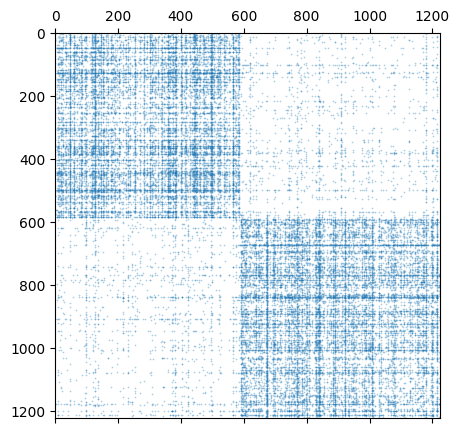

In [153]:
spy(A, marker_size=0.1)
plt.show()

## Trying to replicate the plots by sorting into 4 categories

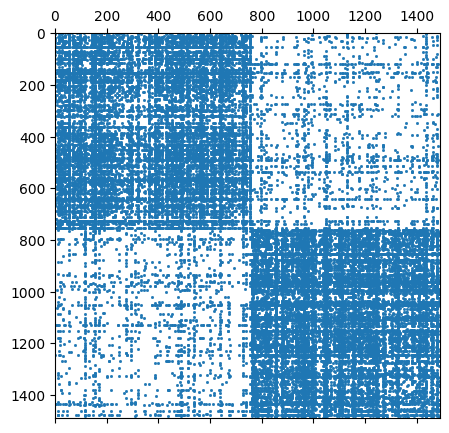

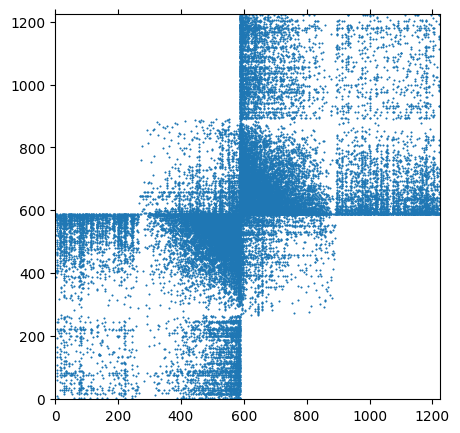

In [22]:
import networkx as nx

G_gml = nx.read_gml("polblogs.gml", destringizer=int).to_undirected(reciprocal=False, as_view=False)

spy(nx.adjacency_matrix(G_gml), marker_size=1)
plt.show()

G_gml.remove_nodes_from(list(nx.isolates(G_gml)))

# Compute the degrees of the nodes
degrees = dict(G_gml.degree())

def check_cross_citation(graph,node):
    neighbors = graph.neighbors(node[0])
    for neighbor in neighbors:
        if node[1] != graph.nodes[neighbor]["value"]:
            return True
    return False

# Sort nodes by increasing degrees within each membership group
nodes_0_0 = [node[0] for node in G_gml.nodes(data="value") if node[1] == 0 and not check_cross_citation(G_gml,node)]
nodes_0_1 = [node[0]  for node in G_gml.nodes(data="value") if node[1] == 0 and check_cross_citation(G_gml,node)]
nodes_1_0 = [node[0]  for node in G_gml.nodes(data="value") if node[1] == 1 and  check_cross_citation(G_gml,node)]
nodes_1_1 = [node[0]  for node in G_gml.nodes(data="value") if node[1] == 1 and not check_cross_citation(G_gml,node)]


nodes_0_0_sorted = nodes_0_0 #  sorted(nodes_0_0, key=lambda node: degrees[node], reverse=True)
nodes_0_1_sorted = sorted(nodes_0_1, key=lambda node: degrees[node])
nodes_1_0_sorted = sorted(nodes_1_0, key=lambda node: degrees[node], reverse=True)
nodes_1_1_sorted = nodes_1_1 # sorted(nodes_1_1, key=lambda node: degrees[node], reverse=False)


# Create the reordered adjacency matrix
reordered_A_gml = nx.adjacency_matrix(G_gml, nodelist=nodes_0_0_sorted + nodes_0_1_sorted + nodes_1_0_sorted + nodes_1_1_sorted).toarray()

spy(reordered_A_gml, marker_size=0.5, origin="lower")
plt.show()

## Trying to sort by degree of connectivity to other category only 

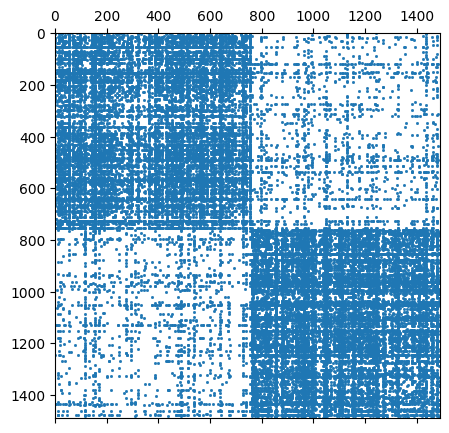

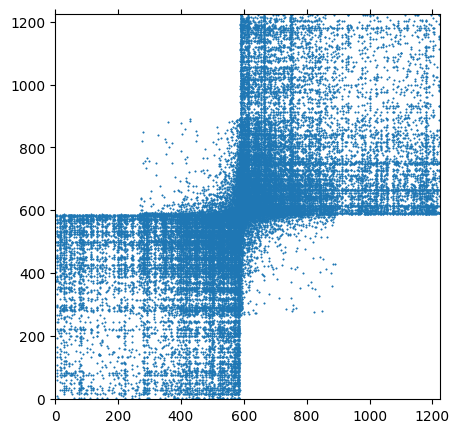

In [32]:
# reload data to make sure no pollution from previous manipulations
G_gml = nx.read_gml("polblogs.gml", destringizer=int).to_undirected(reciprocal=False, as_view=False)

spy(nx.adjacency_matrix(G_gml), marker_size=1)
plt.show()

G_gml.remove_nodes_from(list(nx.isolates(G_gml)))

# Compute the degrees of the nodes
degrees = dict(G_gml.degree())

def check_cross_citation(graph,node):
    neighbors = graph.neighbors(node[0])
    for neighbor in neighbors:
        if node[1] != graph.nodes[neighbor]["value"]:
            return True
    return False

def count_cross_connections(graph,node) -> int:
    neighbors = graph.neighbors(node[0])
    count = 0
    for neighbor in neighbors:
        if node[1] != graph.nodes[neighbor]["value"]:
            count += 1
    return count


inter_connections ={node[0]: count_cross_connections(G_gml,node) for node in G_gml.nodes(data="value")}


# Sort nodes by increasing degrees within each membership group
nodes_0_0 = [node[0] for node in G_gml.nodes(data="value") if node[1] == 0 and not check_cross_citation(G_gml,node)]
nodes_0_1 = [node[0]  for node in G_gml.nodes(data="value") if node[1] == 0 and check_cross_citation(G_gml,node)]
nodes_1_0 = [node[0]  for node in G_gml.nodes(data="value") if node[1] == 1 and  check_cross_citation(G_gml,node)]
nodes_1_1 = [node[0]  for node in G_gml.nodes(data="value") if node[1] == 1 and not check_cross_citation(G_gml,node)]


nodes_0_0_sorted = sorted(nodes_0_0, key=lambda node: inter_connections[node], reverse=True)
nodes_0_1_sorted = sorted(nodes_0_1, key=lambda node: inter_connections[node])
nodes_1_0_sorted = sorted(nodes_1_0, key=lambda node: inter_connections[node], reverse=True)
nodes_1_1_sorted = sorted(nodes_1_1, key=lambda node: inter_connections[node], reverse=False)


# Create the reordered adjacency matrix
reordered_A_gml = nx.adjacency_matrix(G_gml, nodelist=nodes_0_0_sorted + nodes_0_1_sorted + nodes_1_0_sorted + nodes_1_1_sorted).toarray()

spy(reordered_A_gml, marker_size=0.5, origin="lower")
plt.show()

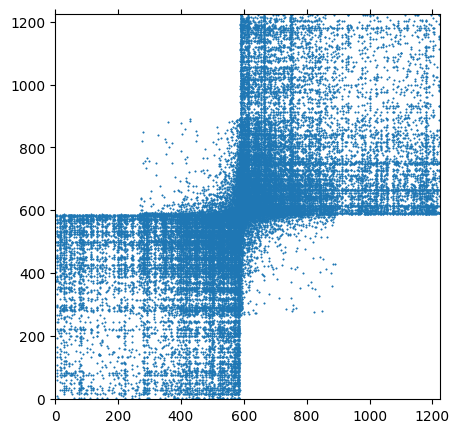

In [35]:
# reload data to make sure no pollution from previous manipulations
G_gml = nx.read_gml("polblogs.gml", destringizer=int).to_undirected(reciprocal=False, as_view=False)


G_gml.remove_nodes_from(list(nx.isolates(G_gml)))

# Compute the number of connection to the opposite party
def count_cross_connections(graph,node) -> int:
    neighbors = graph.neighbors(node[0])
    count = 0
    for neighbor in neighbors:
        if node[1] != graph.nodes[neighbor]["value"]:
            count += 1
    return count


inter_connections ={node[0]: count_cross_connections(G_gml,node) for node in G_gml.nodes(data="value")}


# Sort nodes by increasing degrees within each membership group
nodes_0 = [node[0] for node in G_gml.nodes(data="value") if node[1] == 0 ]
nodes_1 = [node[0]  for node in G_gml.nodes(data="value") if node[1] == 1]


nodes_0_sorted = sorted(nodes_0, key=lambda node: inter_connections[node], reverse=False)
nodes_1_sorted = sorted(nodes_1, key=lambda node: inter_connections[node], reverse=True)


# Create the reordered adjacency matrix
reordered_A_gml = nx.adjacency_matrix(G_gml, nodelist=nodes_0_sorted  + nodes_1_sorted).toarray()

spy(reordered_A_gml, marker_size=0.5, origin="lower")
plt.show()

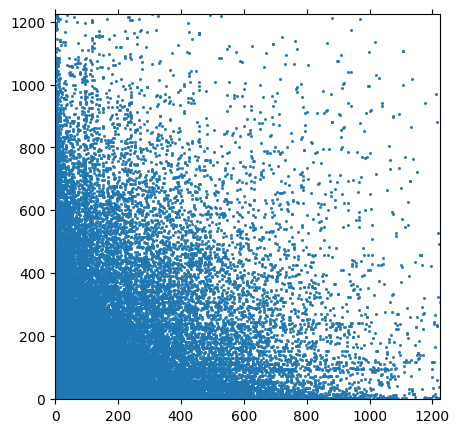

In [16]:
# Compute the degrees of the nodes
degrees = dict(G.degree())



nodes_0_sorted = sorted(G.nodes(), key=lambda node: degrees[node], reverse=True)

# Create the reordered adjacency matrix
reordered_A = nx.adjacency_matrix(G, nodelist=nodes_0_sorted).toarray()

spy(reordered_A, marker_size=1,  ds="default", origin = "lower")
plt.show()

In [7]:
reordered_A.shape

(1224, 1224)

In [8]:
est = SmoothNetHist()
est.fit(reordered_A)
first_hist_olhede = est._first_approximate_graphon_from_adjacency(adjacencyMatrix= reordered_A)

NameError: name 'SmoothNetHist' is not defined

In [ ]:
from pygraphon import HistogramEstimator
est_origin = HistogramEstimator()
est_origin.fit(reordered_A)

In [ ]:
print(est.get_ratio_par())
print("Number of unique parameters in SmoothNetHist:", len(np.unique(est.graphon.get_graphon())))
print("Number of unique parameters in Olhede:", len(np.unique(est_origin.get_graphon().graphon)))

0.1895424836601307
Number of unique parameters in SmoothNetHist: 29
Number of unique parameters in Olhede: 75


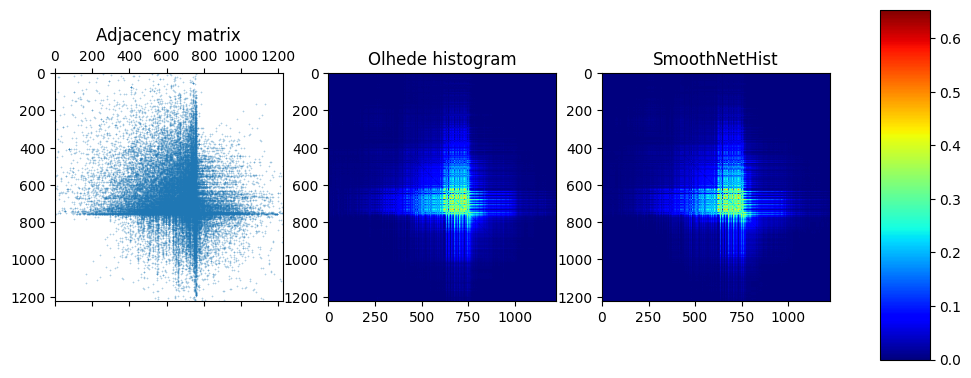

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(est_origin.get_edge_connectivity(), cmap='jet')#, vmin=0, vmax=1)
im2 = ax[2].imshow(est.get_edge_connectivity(), cmap='jet')#, vmin=0, vmax=1)
_ = spy(reordered_A, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("Olhede histogram")
ax[2].set_title("SmoothNetHist")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)

plt.show()

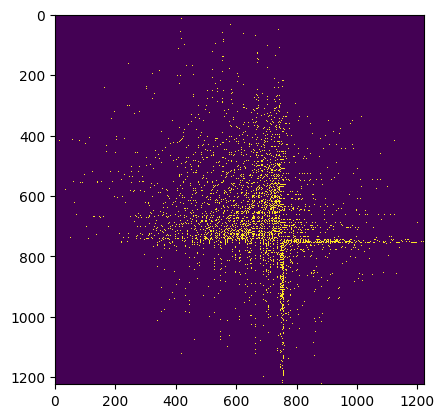

In [ ]:
plt.imshow(reordered_A,  interpolation = "none")

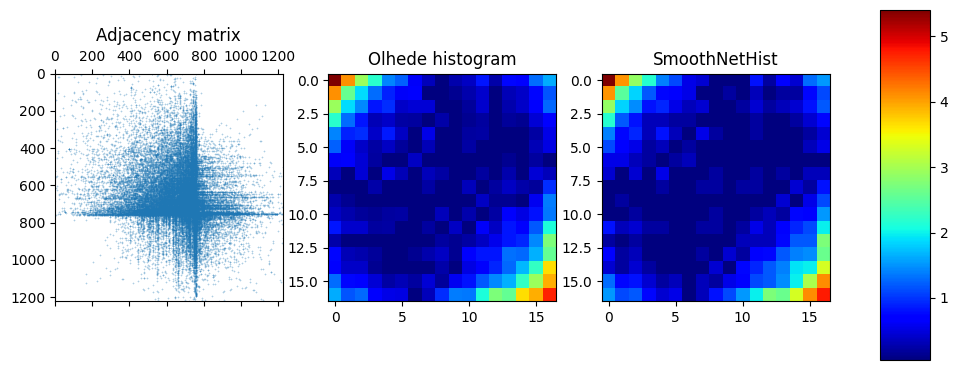

In [ ]:

fig, ax = plt.subplots(1, 3, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(np.sqrt(est_origin.get_graphon().graphon), cmap='jet')#, vmin=0, vmax=1)
im2 = ax[2].imshow(np.sqrt(est.get_graphon().graphon), cmap='jet')#, vmin=0, vmax=1)
_ = spy(reordered_A, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("Olhede histogram")
ax[2].set_title("SmoothNetHist")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)

plt.show()

In [ ]:
graphon_polblogs = est.graphon.get_graphon()
# Get the diagonal elements
diagonal = np.diag(graphon_polblogs)

# Sort the diagonal elements in increasing order and get the sorting indices
sorting_indices = np.argsort(diagonal)

# Permute the rows and columns of the matrix based on the sorting indices
graphon_polblogs_permuted = graphon_polblogs[sorting_indices][:, sorting_indices]

print(graphon_polblogs_permuted.shape)

(17, 17)


C:\Users\verdeyme\AppData\Local\Temp\ipykernel_18388\790563368.py:13: MatplotlibDeprecationWarning: Starting from Matplotlib 3.6, colorbar() will steal space from the mappable's axes, rather than from the current axes, to place the colorbar.  To silence this warning, explicitly pass the 'ax' argument to colorbar().
  plt.colorbar(orientation='vertical')


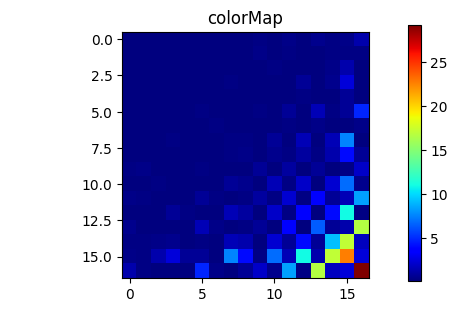

In [ ]:
fig = plt.figure(figsize=(6, 3.2))

ax = fig.add_subplot(111)
ax.set_title('colorMap')
plt.imshow(graphon_polblogs_permuted, cmap='jet')
ax.set_aspect('equal')

cax = fig.add_axes([0.12, 0.1, 0.78, 0.8])
cax.get_xaxis().set_visible(False)
cax.get_yaxis().set_visible(False)
cax.patch.set_alpha(0)
cax.set_frame_on(False)
plt.colorbar(orientation='vertical')
plt.show()